# DL Assignment 01, Section B: Small data CIFAR10 under distribution shift

Seeds and splits used in this report:

* Training seeds: 42, 43, 44. Every number is the mean and sample std over these three runs.
* train_small: 50 images per class from the CIFAR10 training set, drawn with RandomState(0). The first 40 per class are the 400 training images and the last 10 per class are the 100 validation images.
* clean_test: the original 10,000 CIFAR10 test images.
* shifted_test: the corruption pipeline with seed 1234. Validation images get the listed corruptions only, with seed 999.
* Neither test set is used for training, validation or tuning. Each run touches them once, at the end.

If the official shifted test file is available, save it as shifted_test.pt with keys x and y and it will be used instead of the generated one.

In [1]:

import math
import os
import random
import time
import textwrap

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from IPython.display import display


SEEDS = [42, 43, 44]
EPOCHS = 60
BATCH_SIZE = 64
PATIENCE = 20

LEARNING_RATE = 3e-3
WEIGHT_DECAY = 5e-2
LABEL_SMOOTHING = 0.1

CLASSES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed):
    """Set random seeds for reproducible experiments."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


print("Device:", DEVICE)
print("Seeds:", SEEDS)

Device: cuda
Seeds: [42, 43, 44]


## Data

In [2]:

KAGGLE_ROOT = "/kaggle/input/datasets/pankrzysiu/cifar10-python"


def get_cifar(train):
    try:
        return torchvision.datasets.CIFAR10(KAGGLE_ROOT, train=train, download=False)
    except Exception:
        return torchvision.datasets.CIFAR10("./data", train=train, download=True)


train_set = get_cifar(True)
test_set = get_cifar(False)

images = torch.from_numpy(train_set.data).permute(0, 3, 1, 2)
labels = torch.tensor(train_set.targets)

rng = np.random.RandomState(0)
train_idx, val_idx = [], []

# Select 50 images per class: 40 for training and 10 for validation.
for c in range(10):
    chosen = rng.choice(np.where(labels.numpy() == c)[0], 50, replace=False)
    train_idx.extend(chosen[:40])
    val_idx.extend(chosen[40:])

x_train = images[train_idx].float() / 255
y_train = labels[train_idx]

x_val = images[val_idx].float() / 255
y_val = labels[val_idx]

x_clean = torch.from_numpy(test_set.data).permute(0, 3, 1, 2).float() / 255
y_clean = torch.tensor(test_set.targets)

print("Train:", len(x_train), "| Validation:", len(x_val), "| Clean test:", len(x_clean))
print("Images per class in train:", torch.bincount(y_train).tolist())

100%|██████████| 170M/170M [42:21<00:00, 67.1kB/s] 


Train: 400 | Validation: 100 | Clean test: 10000
Images per class in train: [40, 40, 40, 40, 40, 40, 40, 40, 40, 40]


In [3]:

def to_gray(im, g):
    return TF.rgb_to_grayscale(im, num_output_channels=3)


def swap_channels(im, g):
    return im[torch.randperm(3, generator=g)]


def add_noise(im, g):
    noise = torch.randn(im.shape, generator=g) * 0.08
    return (im + noise).clamp(0, 1)


def blur(im, g):
    return TF.gaussian_blur(im, [5, 5], [1.2, 1.2])


EXTRA = {
    "grayscale": to_gray,
    "channel swap": swap_channels,
    "gaussian noise": add_noise,
    "blur": blur
}


def corrupt(x, seed, ops=(), extra_prob=0.0):
    g = torch.Generator().manual_seed(seed)
    out = torch.empty_like(x)
    names = list(EXTRA)

    for i in range(len(x)):
        im = x[i]

        if "rotate" in ops:
            angle = (torch.rand(1, generator=g).item() * 2 - 1) * 25
            im = TF.rotate(im, angle)

        if "light" in ops:
            brightness = 0.5 + torch.rand(1, generator=g).item()
            contrast = 0.5 + torch.rand(1, generator=g).item()
            im = TF.adjust_brightness(im, brightness)
            im = TF.adjust_contrast(im, contrast)

        if "occlude" in ops:
            h = int(torch.randint(8, 17, (1,), generator=g).item())
            w = min(32, 256 // h)

            top = int(torch.randint(0, 33 - h, (1,), generator=g).item())
            left = int(torch.randint(0, 33 - w, (1,), generator=g).item())

            im = im.clone()
            im[:, top:top + h, left:left + w] = 0

        for name in names:
            if name in ops:
                im = EXTRA[name](im, g)

        if torch.rand(1, generator=g).item() < extra_prob:
            idx = int(torch.randint(0, len(names), (1,), generator=g).item())
            im = EXTRA[names[idx]](im, g)

        out[i] = im

    return out


LISTED = ("rotate", "light", "occlude")

if os.path.exists("shifted_test.pt"):
    data = torch.load("shifted_test.pt", map_location="cpu")
    x_shift, y_shift = data["x"], data["y"]
else:
    x_shift = corrupt(x_clean, 1234, LISTED, extra_prob=0.5)
    y_shift = y_clean

x_val_shift = corrupt(x_val, 999, LISTED)

print("Shifted test:", tuple(x_shift.shape))

Shifted test: (10000, 3, 32, 32)


## Model

In [26]:
def block(cin, cout, k, batch_norm=True):
    layers = [nn.Conv2d(cin, cout, k, padding=k // 2, bias=not batch_norm)]

    if batch_norm:
        layers.append(nn.BatchNorm2d(cout))

    layers.append(nn.ReLU(inplace=True))

    return nn.Sequential(*layers)


class Inception(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, batch_norm=True):
        super().__init__()

        self.b1 = block(cin, c1, 1, batch_norm)

        self.b3 = nn.Sequential(
            block(cin, c3r, 1, batch_norm),
            block(c3r, c3, 3, batch_norm)
        )

        self.b5 = nn.Sequential(
            block(cin, c5r, 1, batch_norm),
            block(c5r, c5, 5, batch_norm)
        )

    def forward(self, x):
        return torch.cat([
            self.b1(x),
            self.b3(x),
            self.b5(x)
        ], dim=1)


class Net(nn.Module):
    def __init__(self, batch_norm=True):
        super().__init__()

        self.register_buffer(
            "mean",
            torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "std",
            torch.tensor([0.247, 0.243, 0.261]).view(1, 3, 1, 1)
        )

        self.stem = block(3, 32, 3, batch_norm)
        self.pool = nn.MaxPool2d(2)
        self.inception = Inception(32, 16, 16, 16, 16, 16, batch_norm)
        self.conv = block(48, 32, 3, batch_norm)
        self.fc1 = nn.Linear(32, 64)
        self.drop = nn.Dropout(0.3)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.pool(self.stem(x))
        x = self.pool(self.inception(x))
        x = self.conv(x).mean(dim=(2, 3))
        x = self.drop(F.relu(self.fc1(x)))

        return self.fc2(x)


def summary(model):
    rows, hooks = [], []

    for name, layer in model.named_modules():
        if isinstance(layer, (nn.Conv2d, nn.MaxPool2d, nn.Linear, nn.Dropout)):
            def hook(module, inputs, output, name=name):
                params = sum(p.numel() for p in module.parameters())
                rows.append((name, type(module).__name__, tuple(output.shape), params))

            hooks.append(layer.register_forward_hook(hook))

    model.eval()

    with torch.no_grad():
        model(torch.zeros(1, 3, 32, 32))

    for hook in hooks:
        hook.remove()

    print(f"{'Layer':<22}{'Type':<12}{'Output shape':<22}{'Params':>8}")

    for name, kind, shape, params in rows:
        print(f"{name:<22}{kind:<12}{str(shape):<22}{params:>8,}")

    batch_norm_params = sum(
        p.numel()
        for layer in model.modules() if isinstance(layer, nn.BatchNorm2d)
        for p in layer.parameters()
    )

    print(f"\nBatchNorm parameters: {batch_norm_params:,}")


model = Net()

n_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Trainable parameters:", n_params)
assert n_params <= 1_000_000, "Model exceeds the parameter limit."

summary(model)

Trainable parameters: 27978
Layer                 Type        Output shape            Params
stem.0                Conv2d      (1, 32, 32, 32)            864
pool                  MaxPool2d   (1, 32, 16, 16)              0
inception.b1.0        Conv2d      (1, 16, 16, 16)            512
inception.b3.0.0      Conv2d      (1, 16, 16, 16)            512
inception.b3.1.0      Conv2d      (1, 16, 16, 16)          2,304
inception.b5.0.0      Conv2d      (1, 16, 16, 16)            512
inception.b5.1.0      Conv2d      (1, 16, 16, 16)          6,400
pool                  MaxPool2d   (1, 48, 8, 8)                0
conv.0                Conv2d      (1, 32, 8, 8)           13,824
fc1                   Linear      (1, 64)                  2,112
drop                  Dropout     (1, 64)                      0
fc2                   Linear      (1, 10)                    650

BatchNorm parameters: 288


## Augmentation and training

In [27]:
class ShuffleChannels:
    def __init__(self, p):
        self.p = p

    def __call__(self, x):
        if torch.rand(1).item() < self.p:
            return x[torch.randperm(3)]
        return x


class Noise:
    def __init__(self, p, s):
        self.p = p
        self.s = s

    def __call__(self, x):
        if torch.rand(1).item() < self.p:
            noise = torch.randn_like(x) * torch.rand(1).item() * self.s
            x = (x + noise).clamp(0, 1)
        return x


def make_aug(geo, photo, erase, mild=False):
    steps = []

    if geo:
        if mild:
            steps.extend([
                T.RandomHorizontalFlip(),
                T.RandomRotation(15)
            ])
        else:
            steps.extend([
                T.RandomCrop(32, padding=4, padding_mode="reflect"),
                T.RandomHorizontalFlip(),
                T.RandomRotation(30)
            ])

    if photo:
        if mild:
            steps.append(T.ColorJitter(brightness=0.10, contrast=0.15))
        else:
            steps.extend([
                T.ColorJitter(0.5, 0.5, 0.4),
                T.RandomGrayscale(p=0.15),
                ShuffleChannels(0.15),
                T.RandomApply(
                    [T.GaussianBlur(5, (0.1, 1.5))],
                    p=0.3
                ),
                Noise(0.3, 0.1)
            ])

    if erase:
        if mild:
            steps.append(
                T.RandomErasing(
                    p=0.25,
                    scale=(0.16, 0.16),
                    ratio=(1.0, 1.0),
                    value=0
                )
            )
        else:
            steps.append(
                T.RandomErasing(
                    p=0.6,
                    scale=(0.05, 0.3),
                    ratio=(0.3, 3.3),
                    value=0
                )
            )

    return T.Compose(steps)


def mix(x, targets, p=0.6, a=0.4):
    if torch.rand(1).item() > p:
        return x, targets

    lam = torch.distributions.Beta(a, a).sample().item()
    perm = torch.randperm(len(x))

    x_perm = x[perm]
    targets_perm = targets[perm]

    if torch.rand(1).item() < 0.5:
        x = lam * x + (1 - lam) * x_perm
    else:
        size = int(32 * math.sqrt(1 - lam))
        cy = torch.randint(0, 32, (1,)).item()
        cx = torch.randint(0, 32, (1,)).item()

        y1 = max(cy - size // 2, 0)
        y2 = min(cy + size // 2, 32)
        x1 = max(cx - size // 2, 0)
        x2 = min(cx + size // 2, 32)

        x = x.clone()
        x[:, :, y1:y2, x1:x2] = x_perm[:, :, y1:y2, x1:x2]

        lam = 1 - ((y2 - y1) * (x2 - x1) / (32 * 32))

    targets = lam * targets + (1 - lam) * targets_perm

    return x, targets


CONFIGS = {
    "No augmentation": {
        "geo": 0, "photo": 0, "erase": 0, "mix": 0
    },
    "Geometric only": {
        "geo": 1, "photo": 0, "erase": 0, "mix": 0
    },
    "Photometric only": {
        "geo": 0, "photo": 1, "erase": 0, "mix": 0
    },
    "Geometric + photometric": {
        "geo": 1, "photo": 1, "erase": 0, "mix": 0
    },
    "+ Cutout / Random Erasing": {
        "geo": 1, "photo": 1, "erase": 1, "mix": 0
    },
    "+ Mixup or CutMix + label smoothing": {
        "geo": 1, "photo": 1, "erase": 1, "mix": 1
    },
    "Final (milder augmentation)": {
        "geo": 1, "photo": 1, "erase": 1, "mix": 0, "mild": 1
    }
}


@torch.no_grad()
def get_logits(model, x, bs=1000):
    model.eval()

    return torch.cat([
        model(x[i:i + bs].to(DEVICE)).cpu()
        for i in range(0, len(x), bs)
    ])


def accuracy(model, x, y):
    predictions = get_logits(model, x).argmax(dim=1)
    return (predictions == y).float().mean().item()


def train_one(name, seed):
    cfg = CONFIGS[name]
    set_seed(seed)

    aug = make_aug(cfg["geo"], cfg["photo"], cfg["erase"], cfg.get("mild", 0))
    smooth = LABEL_SMOOTHING if cfg["mix"] else 0.0

    model = Net().to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    n = len(x_train)
    batches = len(range(0, n, BATCH_SIZE))

    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=LEARNING_RATE,
        total_steps=EPOCHS * batches,
        pct_start=0.2
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val = -1.0
    best_state = None
    wait = 0

    for epoch in range(EPOCHS):
        model.train()
        order = torch.randperm(n)
        total_loss = 0.0

        for i in range(0, n, BATCH_SIZE):
            indices = order[i:i + BATCH_SIZE]

            xb = torch.stack([
                aug(x_train[j]) for j in indices
            ])

            targets = F.one_hot(
                y_train[indices],
                num_classes=10
            ).float()

            targets = targets * (1 - smooth) + smooth / 10

            if cfg["mix"]:
                xb, targets = mix(xb, targets)

            xb = xb.to(DEVICE)
            targets = targets.to(DEVICE)

            logits = model(xb)
            loss = -(
                targets * F.log_softmax(logits, dim=1)
            ).sum(dim=1).mean()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()

            total_loss += loss.item() * len(indices)

        val_logits = get_logits(model, x_val)
        val_loss = F.cross_entropy(val_logits, y_val).item()
        val_acc = (val_logits.argmax(1) == y_val).float().mean().item()

        history["train_loss"].append(total_loss / n)
        history["train_acc"].append(accuracy(model, x_train, y_train))
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_val:
            best_val = val_acc
            wait = 0

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
        else:
            wait += 1

            if wait >= PATIENCE:
                break

    model.load_state_dict(best_state)

    return {
        "hist": history,
        "state": best_state,
        "epochs": epoch + 1,
        "train": accuracy(model, x_train, y_train),
        "val": accuracy(model, x_val, y_val),
        "val_shift": accuracy(model, x_val_shift, y_val),
        "clean": accuracy(model, x_clean, y_clean),
        "shift": accuracy(model, x_shift, y_shift)
    }


results = {}


def run_config(name):
    results[name] = []

    for seed in SEEDS:
        start = time.time()
        result = train_one(name, seed)
        results[name].append(result)

        print(
            f"{name} | Seed: {seed} | "
            f"Epochs: {result['epochs']} | "
            f"Val: {result['val']:.3f} | "
            f"Clean: {result['clean']:.3f} | "
            f"Shifted: {result['shift']:.3f} | "
            f"Time: {time.time() - start:.0f}s"
        )


def mean_std(name, key):
    values = np.array([
        result[key] for result in results[name]
    ]) * 100

    return values.mean(), values.std(ddof=1)


def show(name, key):
    mean, std = mean_std(name, key)
    return f"{mean:.2f} ± {std:.2f}"


def per_seed(name):
    return pd.DataFrame([
        {
            "Configuration": name,
            "Seed": seed,
            "Epochs": r["epochs"],
            "Train (%)": r["train"] * 100,
            "Val (%)": r["val"] * 100,
            "Clean test (%)": r["clean"] * 100,
            "Shifted test (%)": r["shift"] * 100
        }
        for seed, r in zip(SEEDS, results[name])
    ]).round(2)

## Look at the data

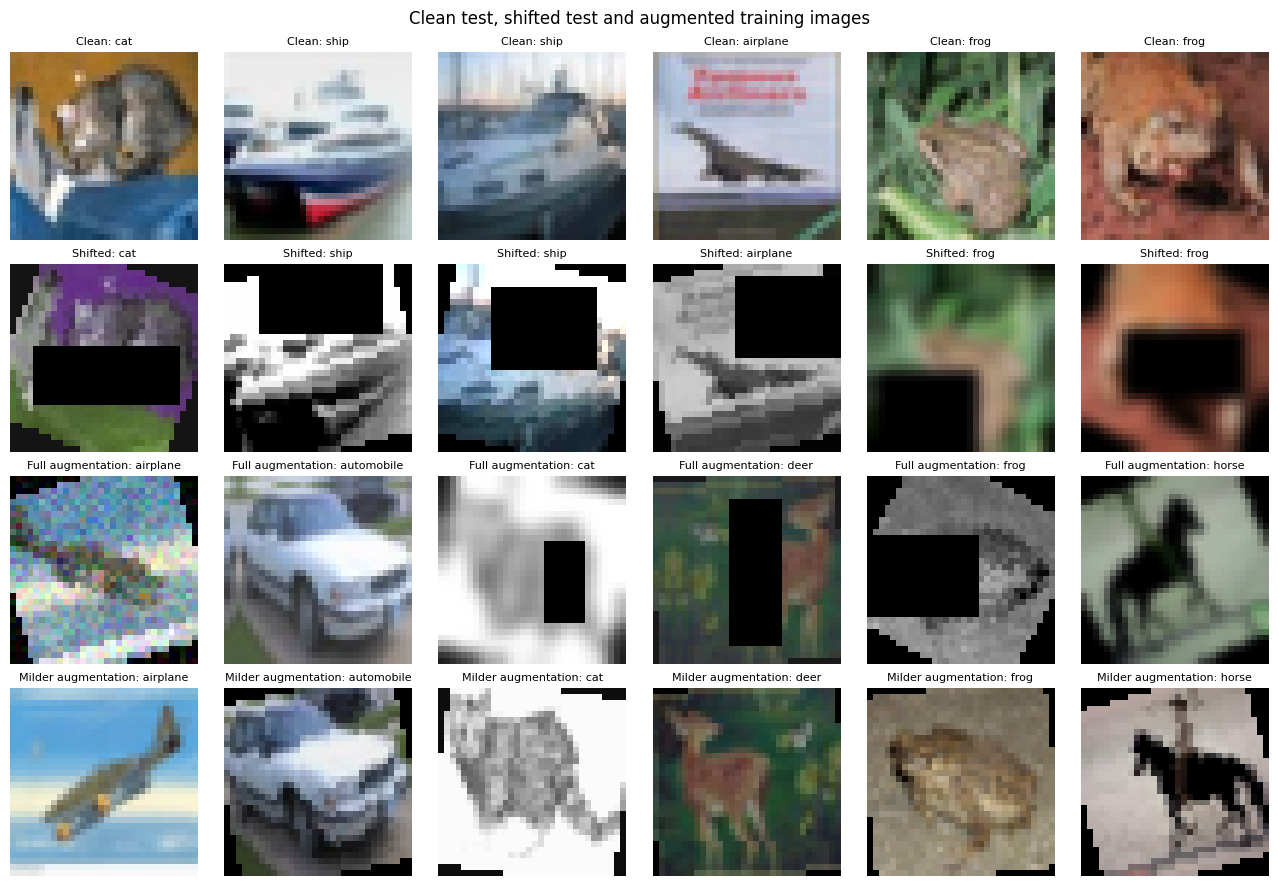

In [28]:
aug_full = make_aug(1, 1, 1)
aug_mild = make_aug(1, 1, 1, mild=True)

fig, axes = plt.subplots(4, 6, figsize=(13, 9))

for k in range(6):
    i = k * 60

    axes[0, k].imshow(x_clean[k].permute(1, 2, 0).numpy())
    axes[0, k].set_title("Clean: " + CLASSES[y_clean[k]], fontsize=8)

    axes[1, k].imshow(x_shift[k].permute(1, 2, 0).numpy())
    axes[1, k].set_title("Shifted: " + CLASSES[y_shift[k]], fontsize=8)

    full = aug_full(x_train[i]).permute(1, 2, 0).clamp(0, 1).numpy()
    axes[2, k].imshow(full)
    axes[2, k].set_title("Full augmentation: " + CLASSES[y_train[i]], fontsize=8)

    mild = aug_mild(x_train[i]).permute(1, 2, 0).clamp(0, 1).numpy()
    axes[3, k].imshow(mild)
    axes[3, k].set_title("Milder augmentation: " + CLASSES[y_train[i]], fontsize=8)

for ax in axes.ravel():
    ax.axis("off")

fig.suptitle("Clean test, shifted test and augmented training images")
plt.tight_layout()
plt.show()

## Part A: Baseline

The network is trained on the 400 images with no augmentation. The table gives train, validation, clean test and shifted test accuracy, and the plots show the learning curves for seed 42.

No augmentation | Seed: 42 | Epochs: 60 | Val: 0.500 | Clean: 0.454 | Shifted: 0.203 | Time: 10s
No augmentation | Seed: 43 | Epochs: 38 | Val: 0.440 | Clean: 0.371 | Shifted: 0.168 | Time: 5s
No augmentation | Seed: 44 | Epochs: 60 | Val: 0.470 | Clean: 0.456 | Shifted: 0.200 | Time: 7s


,Configuration,Seed,Epochs,Train (%),Val (%),Clean test (%),Shifted test (%)
0,No augmentation,42,60,100.00,50.0,45.41,20.26
1,No augmentation,43,38,93.25,44.0,37.07,16.80
2,No augmentation,44,60,100.00,47.0,45.55,20.04


,Train (%),Val (%),Clean test (%),Shifted test (%)
0,97.75 ± 3.90,47.00 ± 3.00,42.68 ± 4.86,19.03 ± 1.94


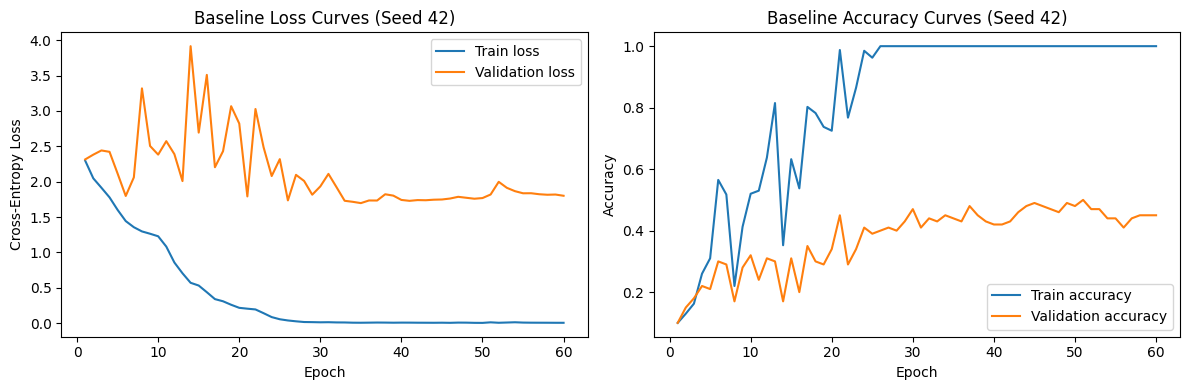

Train accuracy: 97.8%, Clean test accuracy: 42.7%, Gap: 55.1 percentage points.
Clean test accuracy: 42.7%, Shifted test accuracy: 19.0%, Drop: 23.6 percentage points.
Diagnosis: Both overfitting and covariate shift. The model may memorize the small training set and struggle with corrupted test images.


In [14]:

run_config("No augmentation")

name = "No augmentation"

display(per_seed(name))

display(pd.DataFrame([{
    "Train (%)": show(name, "train"),
    "Val (%)": show(name, "val"),
    "Clean test (%)": show(name, "clean"),
    "Shifted test (%)": show(name, "shift")
}]))

h = results[name][0]["hist"]
epochs = range(1, len(h["train_loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, h["train_loss"], label="Train loss")
ax[0].plot(epochs, h["val_loss"], label="Validation loss")
ax[0].set_title("Baseline Loss Curves (Seed 42)")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Cross-Entropy Loss")
ax[0].legend()

ax[1].plot(epochs, h["train_acc"], label="Train accuracy")
ax[1].plot(epochs, h["val_acc"], label="Validation accuracy")
ax[1].set_title("Baseline Accuracy Curves (Seed 42)")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.tight_layout()
plt.show()

train_acc, val_acc, clean_acc, shift_acc = [
    mean_std(name, key)[0]
    for key in ["train", "val", "clean", "shift"]
]

print(
    f"Train accuracy: {train_acc:.1f}%, "
    f"Clean test accuracy: {clean_acc:.1f}%, "
    f"Gap: {train_acc - clean_acc:.1f} percentage points."
)

print(
    f"Clean test accuracy: {clean_acc:.1f}%, "
    f"Shifted test accuracy: {shift_acc:.1f}%, "
    f"Drop: {clean_acc - shift_acc:.1f} percentage points."
)

if train_acc - clean_acc > 10 and clean_acc - shift_acc > 5:
    print(
        "Diagnosis: Both overfitting and covariate shift. "
        "The model may memorize the small training set and "
        "struggle with corrupted test images."
    )
elif train_acc - clean_acc > 10:
    print("Diagnosis: Mainly overfitting.")
else:
    print("Diagnosis: Covariate shift may be the main problem.")

The first gap, between training accuracy and clean test accuracy, is overfitting. With only 400 images the network memorizes them, so training accuracy goes to nearly 100% while validation loss stops improving and rises. The second gap, between clean and shifted accuracy, is covariate shift. Rotation, brightness and contrast changes and occlusion change the input distribution, and a network that never saw such images has no invariance to them. The failure is therefore both.

## Part B: Augmentation Strategy

Chosen augmentations

* Random crop, horizontal flip, and rotation (±30°): Handle changes in object position and rotations up to ±25° in the shifted test set.

* Color jitter: Changes brightness, contrast, and saturation to improve robustness to lighting variations.

* Grayscale, channel shuffle, blur, and noise: Improve robustness to possible unseen corruptions without relying on a single known corruption.

* Random Erasing: Removes a rectangular region covering 5–30% of the image, encouraging the model to learn from multiple object features.

* Mixup or CutMix with label smoothing (0.1): Reduce overfitting and overconfidence when training on only 400 images.

### Q1. Would vertical flip help or hurt?

Vertical flipping would mostly hurt. CIFAR-10 objects usually have a natural upright orientation, such as wheels below cars and the sky above airplanes. Since the test rotation is limited to ±25°, upside-down images are unlikely. Vertical flipping would introduce unrealistic examples and waste the limited model capacity.

### Q2. What is the trade-off of rotating up to ±90° when the test only has ±25°?

Rotating up to ±90° increases rotational diversity but introduces many orientations that are absent from the test set. This can make learning harder with only 400 training images and reduce accuracy on normally oriented objects. A range of ±30° provides a small margin beyond the expected test rotation.

### Q3. Why can too much augmentation reduce accuracy on a small model?

The model has fewer than one million parameters and only 400 training images. Excessive augmentation can remove important class features, create unrealistic examples, and make the task too difficult. The model may underfit because it cannot learn useful patterns from the heavily distorted images.

## Part C: Regularization and Training Design

* Batch Normalization: Applied after each convolution to stabilize training and improve optimization.

* Dropout (0.4): Applied after global average pooling and before the classifier to reduce co-adaptation of high-level features. Applying it between early convolutional layers could disrupt useful low-level feature learning.

* Weight decay (0.05): Used with AdamW to discourage excessively large weights and help control overfitting.

* OneCycle learning-rate schedule: Increases and then decreases the learning rate to support effective optimization within the epoch limit.

* Early stopping (patience 20): Monitors validation accuracy and restores the best checkpoint to reduce overfitting.

* Label smoothing (0.1): Used with Mixup or CutMix to discourage overconfident predictions and complement soft training targets.

* Global average pooling: Replaces large fully connected feature layers, reducing parameter count and overfitting risk.


## Part D: Ablation study

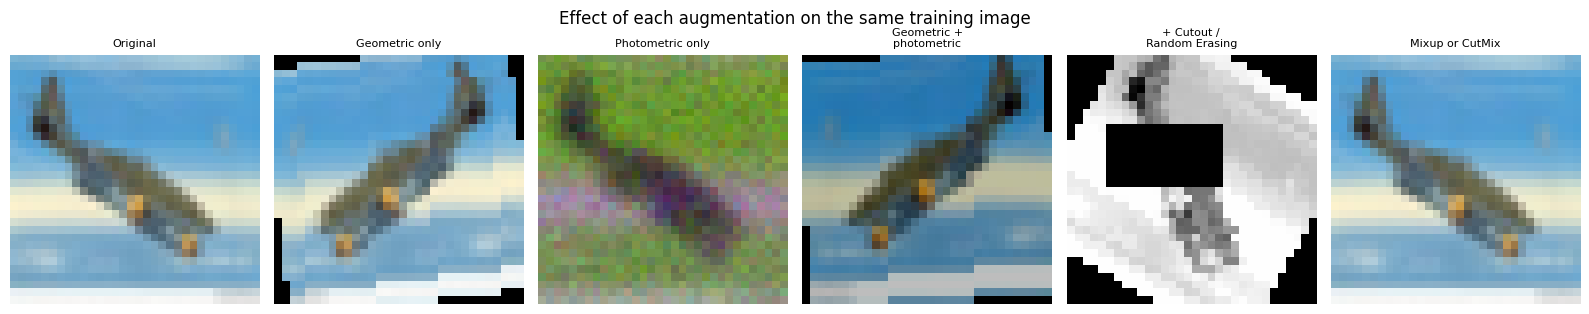

No augmentation | Seed: 42 | Epochs: 60 | Val: 0.430 | Clean: 0.406 | Shifted: 0.164 | Time: 3s
No augmentation | Seed: 43 | Epochs: 60 | Val: 0.410 | Clean: 0.395 | Shifted: 0.166 | Time: 3s
No augmentation | Seed: 44 | Epochs: 60 | Val: 0.450 | Clean: 0.404 | Shifted: 0.157 | Time: 3s


,Configuration,Val Acc,Clean Test,Shifted Test
0,No augmentation,43.00 ± 2.00,40.13 ± 0.59,16.24 ± 0.48
1,Geometric only,38.33 ± 2.52,36.40 ± 2.76,19.29 ± 2.47
2,Photometric only,42.00 ± 3.61,35.01 ± 2.75,20.21 ± 0.25
3,Geometric + photometric,38.33 ± 1.53,32.95 ± 1.67,20.94 ± 1.06
4,+ Cutout / Random Erasing,32.00 ± 4.36,30.32 ± 0.47,23.77 ± 0.38
5,+ Mixup or CutMix + label smoothing,30.33 ± 1.53,26.39 ± 3.13,20.58 ± 3.66
6,Final (milder augmentation),39.67 ± 0.58,38.83 ± 0.64,23.41 ± 0.78
7,Final model (Final (milder augmentation)),39.67 ± 0.58,38.83 ± 0.64,23.41 ± 0.78


Per seed results


,Configuration,Seed,Epochs,Train (%),Val (%),Clean test (%),Shifted test (%)
0,No augmentation,42,60,94.75,43.0,40.57,16.41
1,No augmentation,43,60,87.75,41.0,39.46,16.61
2,No augmentation,44,60,94.75,45.0,40.36,15.69
3,Geometric only,42,51,51.00,41.0,35.24,17.21
4,Geometric only,43,60,64.00,38.0,39.55,22.02
5,Geometric only,44,49,50.75,36.0,34.42,18.63
6,Photometric only,42,60,51.50,46.0,36.30,20.37
7,Photometric only,43,50,46.75,39.0,36.88,20.33
8,Photometric only,44,52,37.50,41.0,31.86,19.92
9,Geometric + photometric,42,60,42.00,38.0,34.44,21.92


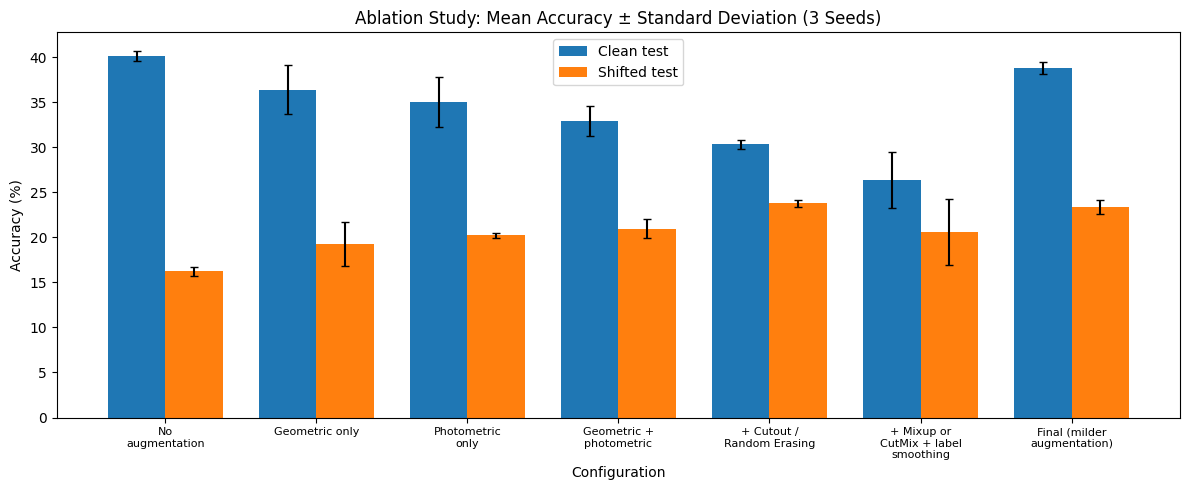

Change in shifted test accuracy (percentage points)
Geometric only: +3.05
Photometric only: +3.97
Geometric + photometric: +0.73
+ Cutout / Random Erasing: +2.83
+ Mixup or CutMix + label smoothing: -3.19

Largest measured gain: Photometric only (+3.97 percentage points).
Reason: This change targets brightness, contrast, and potential colour or noise corruptions.

Final model compared with no augmentation: shifted test +7.17 points, clean test -1.30 points.
Final model selected using validation data: Final (milder augmentation)


In [30]:
sample = x_train[0]
panels = [("Original", sample)]

for k, name in enumerate(list(CONFIGS)[1:5]):
    cfg = CONFIGS[name]
    torch.manual_seed(10 + k)
    panels.append((name, make_aug(cfg["geo"], cfg["photo"], cfg["erase"])(sample)))

pair = torch.stack([x_train[0], x_train[200]])
pair_targets = F.one_hot(y_train[[0, 200]], 10).float()
torch.manual_seed(5)
mixed, _ = mix(pair, pair_targets, p=1.0)
panels.append(("Mixup or CutMix", mixed[0]))

fig, axes = plt.subplots(1, len(panels), figsize=(16, 3.2))

for ax, (title, image) in zip(axes, panels):
    ax.imshow(image.permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(textwrap.fill(title, 16), fontsize=8)
    ax.axis("off")

fig.suptitle("Effect of each augmentation on the same training image")
plt.tight_layout()
plt.show()


for name in CONFIGS:
    if name not in results:
        run_config(name)

names = list(CONFIGS)

# The final model is the best augmented configuration, chosen on validation data only.
final_name = max(
    names[1:],
    key=lambda name: np.mean([(r["val"] + r["val_shift"]) / 2 for r in results[name]])
)

rows = [
    {
        "Configuration": name,
        "Val Acc": show(name, "val"),
        "Clean Test": show(name, "clean"),
        "Shifted Test": show(name, "shift")
    }
    for name in names
]

rows.append({
    "Configuration": f"Final model ({final_name})",
    "Val Acc": show(final_name, "val"),
    "Clean Test": show(final_name, "clean"),
    "Shifted Test": show(final_name, "shift")
})

display(pd.DataFrame(rows))

print("Per seed results")
display(pd.concat([per_seed(name) for name in names], ignore_index=True))


x = np.arange(len(names))
width = 0.38

clean_means, clean_stds = zip(*[mean_std(name, "clean") for name in names])
shift_means, shift_stds = zip(*[mean_std(name, "shift") for name in names])

plt.figure(figsize=(12, 5))
plt.bar(x - width / 2, clean_means, width, yerr=clean_stds, capsize=3, label="Clean test")
plt.bar(x + width / 2, shift_means, width, yerr=shift_stds, capsize=3, label="Shifted test")
plt.xticks(x, [textwrap.fill(name, 14) for name in names], fontsize=8)
plt.xlabel("Configuration")
plt.ylabel("Accuracy (%)")
plt.title("Ablation Study: Mean Accuracy ± Standard Deviation (3 Seeds)")
plt.legend()
plt.tight_layout()
plt.show()


def shifted_mean(name):
    return mean_std(name, "shift")[0]


baseline = shifted_mean("No augmentation")
best_single = max(shifted_mean("Geometric only"), shifted_mean("Photometric only"))

deltas = {
    "Geometric only":
        shifted_mean("Geometric only") - baseline,

    "Photometric only":
        shifted_mean("Photometric only") - baseline,

    "Geometric + photometric":
        shifted_mean("Geometric + photometric") - best_single,

    "+ Cutout / Random Erasing":
        shifted_mean("+ Cutout / Random Erasing")
        - shifted_mean("Geometric + photometric"),

    "+ Mixup or CutMix + label smoothing":
        shifted_mean("+ Mixup or CutMix + label smoothing")
        - shifted_mean("+ Cutout / Random Erasing")
}

matches = {
    "Geometric only":
        "the rotations and positional changes in the shifted test",

    "Photometric only":
        "brightness, contrast, and potential colour or noise corruptions",

    "Geometric + photometric":
        "the rotation and the lighting changes together",

    "+ Cutout / Random Erasing":
        "the rectangular occlusion affecting about 25% of the image",

    "+ Mixup or CutMix + label smoothing":
        "regularization against memorizing the small training set"
}

print("Change in shifted test accuracy (percentage points)")

for name, gain in deltas.items():
    print(f"{name}: {gain:+.2f}")

best_change = max(deltas, key=deltas.get)

if deltas[best_change] > 0:
    print(
        f"\nLargest measured gain: {best_change} "
        f"({deltas[best_change]:+.2f} percentage points)."
    )
    print(f"Reason: This change targets {matches[best_change]}.")
else:
    print("\nNo single change improved the shifted test accuracy.")

total_gain = shifted_mean(final_name) - baseline
clean_change = mean_std(final_name, "clean")[0] - mean_std("No augmentation", "clean")[0]

print(
    f"\nFinal model compared with no augmentation: "
    f"shifted test {total_gain:+.2f} points, clean test {clean_change:+.2f} points."
)
print(f"Final model selected using validation data: {final_name}")

## Part E: Error analysis (final model, seed 42)

,Class,Clean accuracy (%),Shifted accuracy (%)
0,airplane,31.4,14.3
1,automobile,36.6,35.7
2,bird,21.1,13.9
3,cat,18.2,23.8
4,deer,14.2,20.3
5,dog,48.6,10.5
6,frog,51.6,45.0
7,horse,54.8,14.5
8,ship,56.2,32.0
9,truck,58.5,16.7


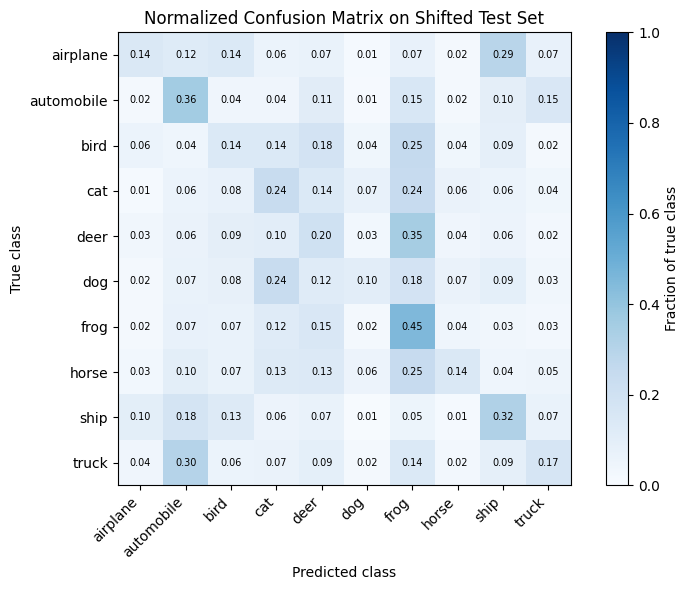

Most confused classes (true class → predicted class):
deer → frog: 0.35 (34.8%)
truck → automobile: 0.30 (30.2%)
airplane → ship: 0.29 (29.0%)
bird → frog: 0.25 (25.0%)
horse → frog: 0.25 (24.6%)


In [31]:

def load(state):
    model = Net().to(DEVICE)
    model.load_state_dict(state)
    model.eval()
    return model


model = load(results[final_name][0]["state"])

logits = get_logits(model, x_shift)
pred = logits.argmax(dim=1)
prob = F.softmax(logits, dim=1)

pred_clean = get_logits(model, x_clean).argmax(dim=1)

per_class = pd.DataFrame({
    "Class": CLASSES,
    "Clean accuracy (%)": [
        round(
            (pred_clean[y_clean == c] == c).float().mean().item() * 100,
            1
        )
        for c in range(10)
    ],
    "Shifted accuracy (%)": [
        round(
            (pred[y_shift == c] == c).float().mean().item() * 100,
            1
        )
        for c in range(10)
    ]
})

display(per_class)


cm = confusion_matrix(
    y_shift.numpy(),
    pred.numpy(),
    labels=list(range(10)),
    normalize="true"
)

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Fraction of true class")

plt.xticks(range(10), CLASSES, rotation=45, ha="right")
plt.yticks(range(10), CLASSES)

for i in range(10):
    for j in range(10):
        plt.text(
            j, i, f"{cm[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if cm[i, j] > 0.5 else "black"
        )

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Normalized Confusion Matrix on Shifted Test Set")
plt.tight_layout()
plt.show()


pairs = sorted(
    [
        (cm[i, j], i, j)
        for i in range(10)
        for j in range(10)
        if i != j
    ],
    reverse=True
)[:5]

print("Most confused classes (true class → predicted class):")

for fraction, i, j in pairs:
    print(
        f"{CLASSES[i]} → {CLASSES[j]}: "
        f"{fraction:.2f} ({fraction * 100:.1f}%)"
    )

Why these classes are confused: at 32 by 32 pixels the pairs at the top of the list share shape, texture, colour and background, for example cat and dog, deer and horse, automobile and truck, airplane and ship. Occlusion, blur and darkness remove the small details (ears, snout, wheels, wings) that separate them.

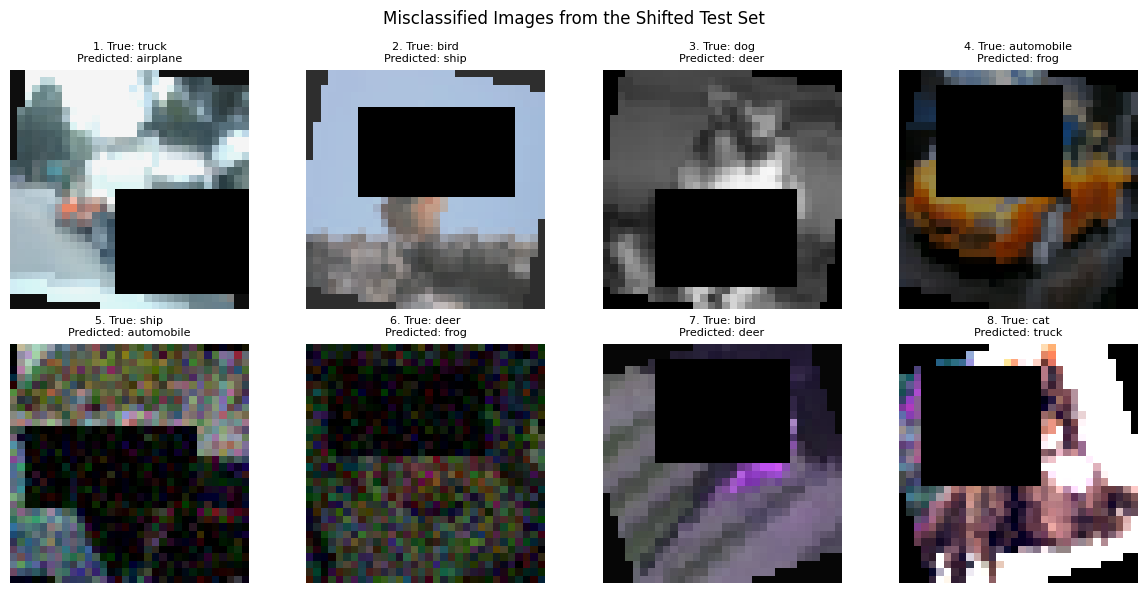

1. truck predicted as airplane (confidence: 0.21) — 25% of image is blacked out, possibly noisy
2. bird predicted as ship (confidence: 0.34) — 25% of image is blacked out, possibly noisy
3. dog predicted as deer (confidence: 0.36) — 32% of image is blacked out, very dark, little colour variation, possibly noisy
4. automobile predicted as frog (confidence: 0.28) — 38% of image is blacked out, very dark
5. ship predicted as automobile (confidence: 0.46) — very dark, possibly noisy
6. deer predicted as frog (confidence: 0.62) — very dark, low contrast
7. bird predicted as deer (confidence: 0.34) — 36% of image is blacked out, very dark, possibly noisy
8. cat predicted as truck (confidence: 0.41) — 36% of image is blacked out, possibly noisy


In [32]:

similar = [
    {"cat", "dog"}, {"deer", "horse"}, {"automobile", "truck"},
    {"airplane", "ship"}, {"airplane", "bird"}, {"bird", "frog"}
]

kernel = torch.tensor([
    [0., 1., 0.],
    [1., -4., 1.],
    [0., 1., 0.]
]).view(1, 1, 3, 3)


def why(im, true, predicted):
    notes = []
    gray = im.mean(dim=0)
    pixels = im.max(dim=0).values

    black = (pixels < 0.03).float().mean().item()

    if black > 0.15:
        notes.append(f"{black * 100:.0f}% of image is blacked out")
    if gray.mean() < 0.3:
        notes.append("very dark")
    if gray.mean() > 0.7:
        notes.append("very bright")
    if gray.std() < 0.12:
        notes.append("low contrast")
    if (im.max(dim=0).values - im.min(dim=0).values).mean() < 0.02:
        notes.append("little colour variation")

    sharpness = F.conv2d(gray[None, None], kernel).var().item()

    if sharpness > 0.05:
        notes.append("possibly noisy")
    elif sharpness < 0.0015:
        notes.append("possibly blurred")

    if {CLASSES[true], CLASSES[predicted]} in similar:
        notes.append("visually similar classes")

    return ", ".join(notes) if notes else "complex background or unusual pose"


wrong = torch.where(pred != y_shift)[0].numpy()

if len(wrong) < 8:
    print(f"Only {len(wrong)} misclassified images are available.")
    pick = wrong
else:
    pick = np.random.RandomState(0).choice(wrong, 8, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for k, (ax, i) in enumerate(zip(axes.ravel(), pick), 1):
    ax.imshow(x_shift[i].permute(1, 2, 0).numpy())
    ax.set_title(
        f"{k}. True: {CLASSES[y_shift[i].item()]}\n"
        f"Predicted: {CLASSES[pred[i].item()]}",
        fontsize=8
    )
    ax.axis("off")

for ax in axes.ravel()[len(pick):]:
    ax.axis("off")

fig.suptitle("Misclassified Images from the Shifted Test Set")
plt.tight_layout()
plt.show()

for k, i in enumerate(pick, 1):
    true = y_shift[i].item()
    predicted = pred[i].item()
    confidence = prob[i].max().item()

    print(
        f"{k}. {CLASSES[true]} predicted as {CLASSES[predicted]} "
        f"(confidence: {confidence:.2f}) — "
        f"{why(x_shift[i], true, predicted)}"
    )

Hidden corruption test. Each candidate corruption below is applied alone to the clean test set. The listed corruptions were never used for this, and the network was trained with augmentations that were chosen without knowing which one is hidden.

,Corruption,No augmentation,Final model
0,clean,40.13 ± 0.59,38.83 ± 0.64
1,grayscale,33.79 ± 1.19,31.71 ± 0.82
2,channel swap,31.07 ± 1.29,28.57 ± 1.07
3,gaussian noise,23.75 ± 0.71,27.08 ± 2.80
4,blur,24.46 ± 1.72,24.97 ± 0.45


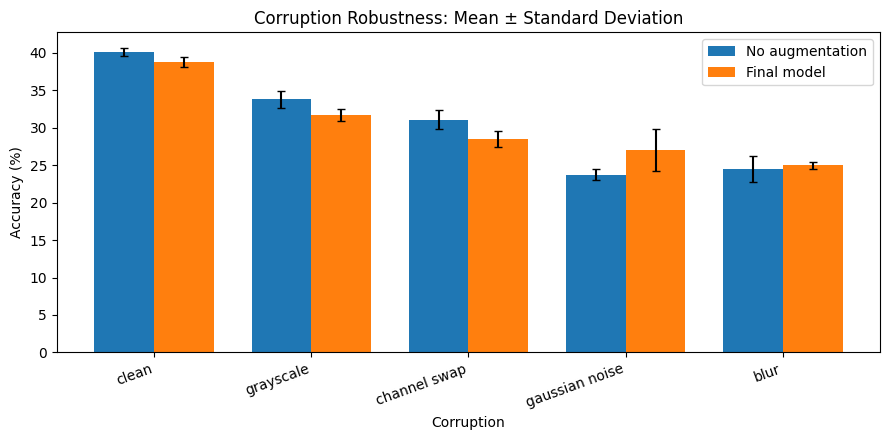

clean: Final 38.8% vs Baseline 40.1% (-1.3 points)
grayscale: Final 31.7% vs Baseline 33.8% (-2.1 points)
channel swap: Final 28.6% vs Baseline 31.1% (-2.5 points)
gaussian noise: Final 27.1% vs Baseline 23.8% (+3.3 points)
blur: Final 25.0% vs Baseline 24.5% (+0.5 points)
No improvement over baseline: clean, grayscale, channel swap
Hardest corruption for final model: blur


In [33]:

base_models = [load(r["state"]) for r in results["No augmentation"]]
final_models = [load(r["state"]) for r in results[final_name]]

sets = {"clean": x_clean}
sets.update({name: corrupt(x_clean, 2024, (name,)) for name in EXTRA})

rows = []
base_mean, base_std, final_mean, final_std = [], [], [], []

for name, images in sets.items():
    base_acc = np.array([accuracy(m, images, y_clean) for m in base_models]) * 100
    final_acc = np.array([accuracy(m, images, y_clean) for m in final_models]) * 100

    rows.append({
        "Corruption": name,
        "No augmentation": f"{base_acc.mean():.2f} ± {base_acc.std(ddof=1):.2f}",
        "Final model": f"{final_acc.mean():.2f} ± {final_acc.std(ddof=1):.2f}"
    })

    base_mean.append(base_acc.mean())
    base_std.append(base_acc.std(ddof=1))
    final_mean.append(final_acc.mean())
    final_std.append(final_acc.std(ddof=1))

display(pd.DataFrame(rows))


x = np.arange(len(sets))
width = 0.38

plt.figure(figsize=(9, 4.5))
plt.bar(x - width / 2, base_mean, width, yerr=base_std,
        capsize=3, label="No augmentation")
plt.bar(x + width / 2, final_mean, width, yerr=final_std,
        capsize=3, label="Final model")

plt.xticks(x, list(sets), rotation=20, ha="right")
plt.xlabel("Corruption")
plt.ylabel("Accuracy (%)")
plt.title("Corruption Robustness: Mean ± Standard Deviation")
plt.legend()
plt.tight_layout()
plt.show()


weak = []

for name, base, final in zip(sets, base_mean, final_mean):
    difference = final - base
    print(f"{name}: Final {final:.1f}% vs Baseline {base:.1f}% ({difference:+.1f} points)")

    if difference <= 0:
        weak.append(name)

if weak:
    print("No improvement over baseline:", ", ".join(weak))
else:
    print("Final model outperforms baseline on every tested corruption.")

hardest = list(sets)[1 + int(np.argmin(final_mean[1:]))]
print("Hardest corruption for final model:", hardest)

## Part F: Test time augmentation (bonus)

In [34]:

def shift_img(x, dx, dy):
    x = F.pad(x, (2, 2, 2, 2), mode="reflect")
    return x[:, :, 2 + dy:34 + dy, 2 + dx:34 + dx]


VIEWS = [
    (0, 0, 0), (1, 0, 0),
    (0, 2, 0), (0, -2, 0),
    (0, 0, 2), (0, 0, -2),
    (1, 2, 0), (1, -2, 0)
]


@torch.no_grad()
def tta_probs(model, x, batch_size=500):
    model.eval()
    outputs = []

    for i in range(0, len(x), batch_size):
        xb = x[i:i + batch_size].to(DEVICE)
        probs = 0

        for flip, dx, dy in VIEWS:
            xi = torch.flip(xb, [3]) if flip else xb

            if dx or dy:
                xi = shift_img(xi, dx, dy)

            probs += F.softmax(model(xi), dim=1)

        outputs.append((probs / len(VIEWS)).cpu())

    return torch.cat(outputs)


def timed(fn):
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start = time.time()
    result = fn()

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    return result, time.time() - start


plain_acc, tta_acc = [], []
plain_time, tta_time = [], []

for model in final_models:
    logits, elapsed = timed(lambda: get_logits(model, x_shift))
    plain_acc.append((logits.argmax(1) == y_shift).float().mean().item() * 100)
    plain_time.append(elapsed)

    probs, elapsed = timed(lambda: tta_probs(model, x_shift))
    tta_acc.append((probs.argmax(1) == y_shift).float().mean().item() * 100)
    tta_time.append(elapsed)


print(
    f"Without TTA: {np.mean(plain_acc):.2f} ± "
    f"{np.std(plain_acc, ddof=1):.2f}%"
)
print(
    f"With TTA ({len(VIEWS)} views): {np.mean(tta_acc):.2f} ± "
    f"{np.std(tta_acc, ddof=1):.2f}%"
)
print(f"Accuracy change: {np.mean(tta_acc) - np.mean(plain_acc):+.2f} points")

slowdown = np.mean(tta_time) / max(np.mean(plain_time), 1e-9)

print(
    f"Inference time for {len(x_shift)} images: "
    f"{np.mean(plain_time):.2f}s without TTA, "
    f"{np.mean(tta_time):.2f}s with TTA "
    f"({slowdown:.1f}x slower)"
)

Without TTA: 23.41 ± 0.78%
With TTA (8 views): 23.75 ± 0.80%
Accuracy change: +0.34 points
Inference time for 10000 images: 0.15s without TTA, 0.95s with TTA (6.5x slower)


Averaging the softmax over several flipped and shifted copies reduces the variance of a single prediction, so accuracy usually rises slightly. The price is one forward pass per view, so inference costs about as many times more as there are views. Whether this is worth it depends on how large the printed gain is compared with the seed std.

## Summary 

In [36]:
shift_mean, shift_std = mean_std(final_name, "shift")
clean_mean, clean_std = mean_std(final_name, "clean")
val_mean, val_std = mean_std(final_name, "val")
base_mean, base_std = mean_std("No augmentation", "shift")

print(f"Final shifted test accuracy: {shift_mean:.2f} ± {shift_std:.2f}%")
print(f"Final clean test accuracy: {clean_mean:.2f} ± {clean_std:.2f}%")
print(f"Validation accuracy: {val_mean:.2f} ± {val_std:.2f}%")
print(f"Baseline shifted test accuracy: {base_mean:.2f} ± {base_std:.2f}%")
print(f"Improvement over baseline: {shift_mean - base_mean:+.2f} points")
print(f"Seeds: {SEEDS}")
print(f"Final configuration: {final_name}")

if deltas[best_change] > 0:
    print(f"Most helpful change: {best_change} ({deltas[best_change]:+.2f} points)")
else:
    print("Most helpful change: none, no single change improved the shifted test accuracy")

print(f"Trainable parameters: {n_params:,}")


Final shifted test accuracy: 23.41 ± 0.78%
Final clean test accuracy: 38.83 ± 0.64%
Validation accuracy: 39.67 ± 0.58%
Baseline shifted test accuracy: 16.24 ± 0.48%
Improvement over baseline: +7.17 points
Seeds: [42, 43, 44]
Final configuration: Final (milder augmentation)
Most helpful change: Photometric only (+3.97 points)
Trainable parameters: 27,978
